# 01 — Datos reales: precio de bolsa (XM) y resoluciones CREG

**Problema.** Decidir cuándo cargar o descargar una batería según el precio de bolsa horario.

**Fuentes**
- **XM**, *Precio de Bolsa Nacional* (`PrecBolsNaci`), horario, en COP/kWh. API pública
  `https://servapibi.xm.com.co/hourly` (la misma que usa `pydataxm`; se llama con `requests`
  para no agregar dependencias). Rango: 2024-01-01 → 2026-10-31.
- **CREG**, gestor normativo *Alejandría* (corpus del RAG): resoluciones 101 113 de 2026 (SAEB),
  098 de 2019 (SAEB), 174 de 2021 (autogeneración) y 024 de 1995 (reglas de la bolsa).

**Plan B.** `src/datos.py` guarda todo en `data/raw/`. Si la API falla, se usan esos archivos.

In [1]:
import sys
sys.path.insert(0, "../src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 160)

In [2]:
import datos

# Si data/raw/precio_bolsa_xm.csv no existe, se descarga de la API de XM
df = datos.load_prices()
print(df.shape)
df.head()

(24840, 3)


,fecha,hora,precio
0,2024-01-01,0,251.91161
1,2024-01-01,1,251.91161
2,2024-01-01,2,251.91161
3,2024-01-01,3,281.91161
4,2024-01-01,4,281.91161


## 1. Calidad de los datos

In [3]:
print("Días completos:", df["fecha"].nunique())
print("Rango:", df["fecha"].min().date(), "→", df["fecha"].max().date())
print("Valores nulos:", df["precio"].isna().sum())
df["precio"].describe().round(1)

Días completos: 1035
Rango: 2024-01-01 → 2026-10-31
Valores nulos: 0


count    24840.0
mean       468.4
std        391.7
min         95.9
25%        162.2
50%        355.4
75%        666.1
max       2675.6
Name: precio, dtype: float64

## 2. Serie de tiempo

El precio de 2024 muestra el efecto del fenómeno de **El Niño** (picos > 1.000 COP/kWh). Por eso,
en el MDP, el nivel de precio se mide **relativo al promedio del día anterior** y no en valor absoluto.

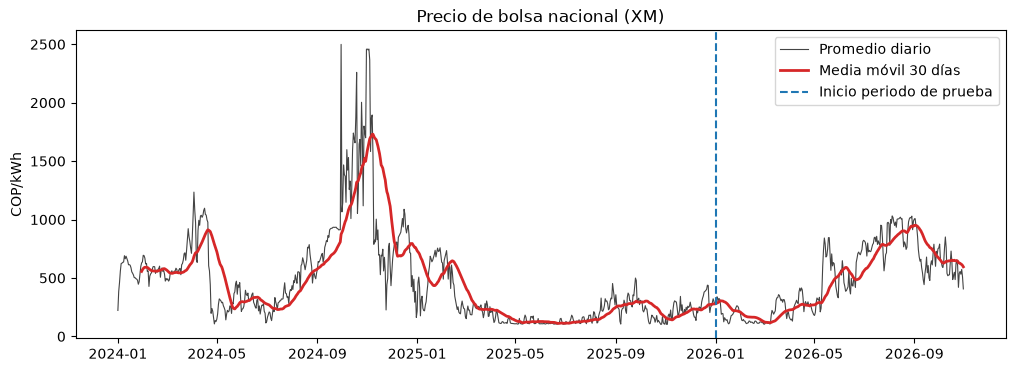

In [4]:
M = datos.price_matrix(df)            # una fila por día, 24 columnas
daily = M.mean(axis=1)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(daily.index, daily, lw=0.8, color="#444", label="Promedio diario")
ax.plot(daily.rolling(30).mean(), lw=2, color="#d62728", label="Media móvil 30 días")
ax.axvline(pd.Timestamp("2026-01-01"), ls="--", label="Inicio periodo de prueba")
ax.set_ylabel("COP/kWh"); ax.set_title("Precio de bolsa nacional (XM)"); ax.legend()
plt.show()

## 3. Perfil horario

La batería gana dinero si compra barato y vende caro. El **perfil horario** muestra que el precio
sube en la noche (18–21 h), que es cuando conviene descargar. Porque es cuando la energia esta mas cara, entonces cargar implicaria gastar mas

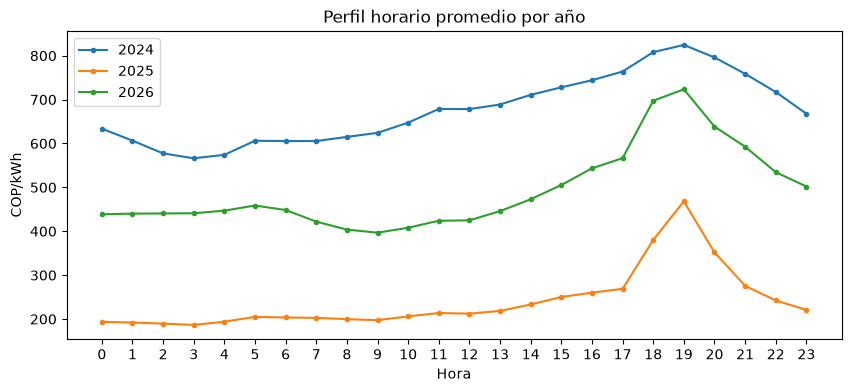

In [5]:
fig, ax = plt.subplots(figsize=(10, 4))
for year, g in M.groupby(M.index.year):
    ax.plot(range(24), g.mean(axis=0), marker="o", ms=3, label=str(year))
ax.set_xlabel("Hora"); ax.set_ylabel("COP/kWh"); ax.set_xticks(range(24))
ax.set_title("Perfil horario promedio por año"); ax.legend()
plt.show()

In [6]:
spread = (M.max(axis=1) - M.min(axis=1))
print(f"Diferencial diario (máx - mín) promedio: {spread.mean():.1f} COP/kWh")
print(f"Días con diferencial < 10% del precio medio: {(spread / M.mean(axis=1) < 0.10).mean():.1%}")

Diferencial diario (máx - mín) promedio: 328.0 COP/kWh
Días con diferencial < 10% del precio medio: 17.7%


## 4. División entrenamiento / prueba (temporal)

| Periodo | Fechas | Uso |
|---|---|---|
| Entrenamiento | 2024-01-01 → 2025-12-31 | Q-learning, estimar el modelo para iteración de valor, horario fijo |
| Prueba | 2026-01-01 → 2026-10-31 | Métricas reportadas (datos no vistos) |

In [7]:
train, test = M[M.index <= "2025-12-31"], M[M.index > "2025-12-31"]
print("Días de entrenamiento:", len(train), "| Días de prueba:", len(test))

Días de entrenamiento: 731 | Días de prueba: 304


## 5. Corpus del RAG (CREG)

In [8]:
docs = datos.load_documents()
for d in docs:
    print(f"{d['title']:<65} {len(d['content']):>9,} caracteres  {d['url']}")

Resolución CREG 101 113 de 2026 (SAEB en el SIN)                    261,951 caracteres  https://gestornormativo.creg.gov.co/gestor/entorno/docs/resolucion_creg_101-113_2026.htm
Resolución CREG 098 de 2019 (SAEB, derogada)                         64,469 caracteres  https://gestornormativo.creg.gov.co/gestor/entorno/docs/resolucion_creg_0098_2019.htm
Resolución CREG 174 de 2021 (autogeneración a pequeña escala)       175,822 caracteres  https://gestornormativo.creg.gov.co/gestor/entorno/docs/resolucion_creg_0174_2021.htm
Resolución CREG 024 de 1995 (reglas de la bolsa de energía)         194,950 caracteres  https://gestornormativo.creg.gov.co/gestor/entorno/docs/resolucion_creg_0024_1995.htm
